# Sprint 3 — Milestone 9
# Correlation Study

## Objective

Investigate relationships between dataset characteristics
and pneumonia diagnosis.

Questions:

- Does age relate to pneumonia?
- Does sex relate to pneumonia?
- Does image brightness relate to pneumonia?
- Does bounding-box area relate to the target?
- Are there relationships between image characteristics
  and diagnosis?

Important:

Correlation does not imply causation.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.labels import load_labels

from src.analysis.image_analysis import (
    analyze_image_properties
)

from src.analysis.metadata_analysis import (
    analyze_metadata
)

from src.analysis.correlation_analysis import (
    build_correlation_dataset,
    calculate_correlation_matrix
)

NEW LABELS.PY LOADED


In [2]:
image_dir = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images"
)

csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)

In [3]:
labels, stats = load_labels(
    csv_path
)

print(
    "Number of images/patient IDs:",
    stats["num_patients"]
)

print(
    "Positive cases:",
    stats["positive_cases"]
)

print(
    "Negative cases:",
    stats["negative_cases"]
)

Number of images/patient IDs: 26684
Positive cases: 6012
Negative cases: 20672


In [4]:
metadata_df = analyze_metadata(
    image_dir=image_dir,
    sample_size=1000,
    random_state=42
)

In [5]:
image_df = analyze_image_properties(
    image_dir
)

print(
    "Image records:",
    len(image_df)
)

Image records: 26684


In [6]:
from src.analysis.pixel_analysis import (
    analyze_pixel_statistics
)

pixel_df = analyze_pixel_statistics(
    image_dir=image_dir,
    sample_size=1000,
    random_state=42
)

print(
    "Pixel records:",
    len(pixel_df)
)

Pixel records: 1000


In [7]:
from src.analysis.bounding_box_analysis import (
    create_bounding_box_dataframe
)

bbox_df = create_bounding_box_dataframe(
    labels
)

print(
    "Bounding boxes:",
    len(bbox_df)
)

Bounding boxes: 9555


In [8]:
print("metadata:", metadata_df.columns.tolist())
print("pixel:", pixel_df.columns.tolist())
print("bbox:", bbox_df.columns.tolist())
print("image:", image_df.columns.tolist())

metadata: ['patient_id', 'age', 'sex', 'view_position', 'pixel_spacing_x', 'pixel_spacing_y', 'manufacturer', 'modality']
pixel: ['patient_id', 'mean_intensity', 'median_intensity', 'std_intensity', 'min_intensity', 'max_intensity', 'dynamic_range']
bbox: ['patient_id', 'x', 'y', 'width', 'height', 'area', 'aspect_ratio', 'center_x', 'center_y']
image: ['patient_id', 'height', 'width', 'aspect_ratio', 'pixel_spacing_x', 'pixel_spacing_y', 'view_position']


In [9]:
correlation_df = build_correlation_dataset(
    labels=labels,
    metadata_df=metadata_df,
    pixel_df=pixel_df,
    bbox_df=bbox_df,
    image_df=image_df
)

print(
    correlation_df.shape
)

correlation_df.head()

(26684, 10)


,patient_id,target,age_years,sex_numeric,mean_intensity,bbox_count,total_bbox_area,max_bbox_area,width,height
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,0,NaN,NaN,NaN,0.0,0.0,0.0,1024,1024
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,0,NaN,NaN,NaN,0.0,0.0,0.0,1024,1024
2,00322d4d-1c29-4943-afc9-b6754be640eb,0,NaN,NaN,NaN,0.0,0.0,0.0,1024,1024
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,0,NaN,NaN,NaN,0.0,0.0,0.0,1024,1024
4,00436515-870c-4b36-a041-de91049b9ab4,1,NaN,NaN,NaN,2.0,196695.0,115968.0,1024,1024


In [10]:
correlation_df.isna().sum()

patient_id             0
target                 0
age_years          25684
sex_numeric        25684
mean_intensity     25684
bbox_count             0
total_bbox_area        0
max_bbox_area          0
width                  0
height                 0
dtype: int64

In [11]:
correlation_matrix = calculate_correlation_matrix(
    correlation_df
)

correlation_matrix

,target,age_years,sex_numeric,mean_intensity,bbox_count,total_bbox_area,max_bbox_area,width,height
target,1.000000,0.009681,0.052386,-0.097853,0.991829,0.989255,0.989255,NaN,NaN
age_years,0.009681,1.000000,0.021629,0.229295,0.007990,0.009605,0.010405,NaN,NaN
sex_numeric,0.052386,0.021629,1.000000,-0.042164,0.050520,0.053654,0.052992,NaN,NaN
mean_intensity,-0.097853,0.229295,-0.042164,1.000000,-0.085510,-0.086228,-0.089290,NaN,NaN
bbox_count,0.991829,0.007990,0.050520,-0.085510,1.000000,0.993565,0.988830,NaN,NaN
total_bbox_area,0.989255,0.009605,0.053654,-0.086228,0.993565,1.000000,0.998817,NaN,NaN
max_bbox_area,0.989255,0.010405,0.052992,-0.089290,0.988830,0.998817,1.000000,NaN,NaN
width,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
height,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


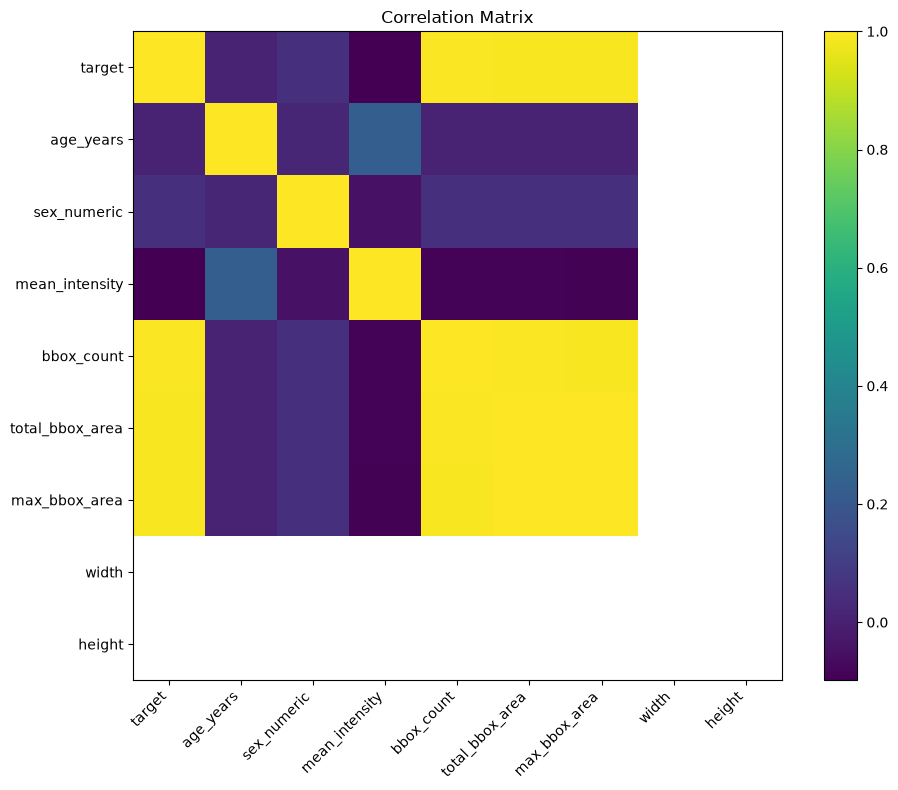

In [12]:
plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title(
    "Correlation Matrix"
)

plt.tight_layout()

plt.show()

In [13]:
# Relationship 1 — Age vs Pneumonia

age_by_target = (
    correlation_df
    .dropna(subset=["age_years"])
    .groupby("target")["age_years"]
    .describe()
)

age_by_target

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,801.0,46.881398,17.440532,2.0,34.0,49.0,60.0,155.0
1,199.0,47.140704,16.923783,9.0,33.5,49.0,60.0,78.0


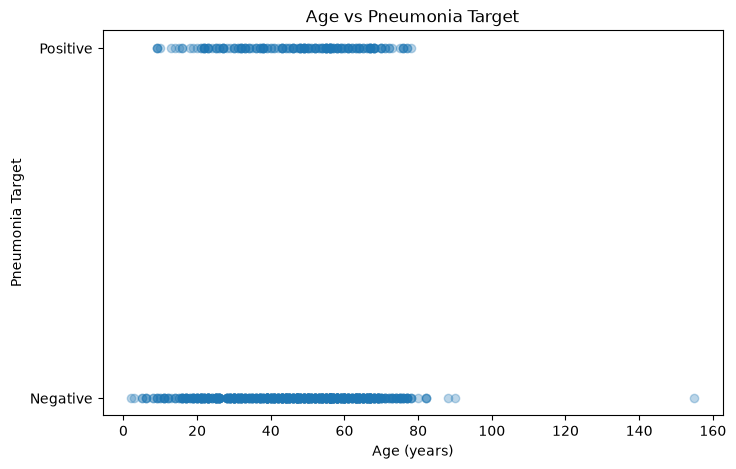

In [14]:
plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    correlation_df["age_years"],
    correlation_df["target"],
    alpha=0.3
)

plt.xlabel(
    "Age (years)"
)

plt.ylabel(
    "Pneumonia Target"
)

plt.title(
    "Age vs Pneumonia Target"
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.show()

In [15]:
# Relationship 2 — Sex vs Pneumonia

sex_target = pd.crosstab(
    correlation_df["sex_numeric"],
    correlation_df["target"],
    normalize="index"
) * 100

sex_target

target,0,1
sex_numeric,,
0.0,82.488479,17.511521
1.0,78.268551,21.731449


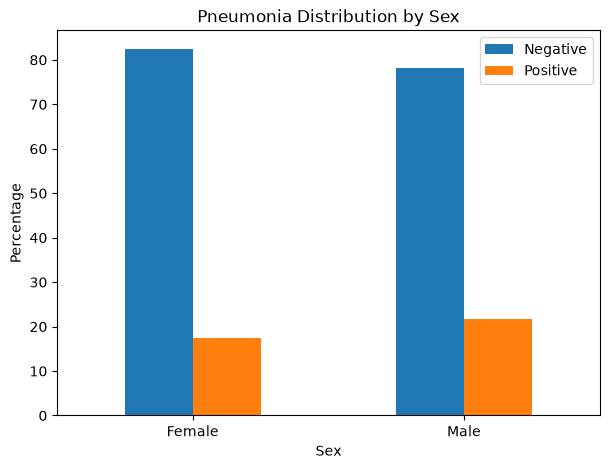

In [16]:
sex_target.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title(
    "Pneumonia Distribution by Sex"
)

plt.xlabel(
    "Sex"
)

plt.ylabel(
    "Percentage"
)

plt.xticks(
    [0, 1],
    ["Female", "Male"],
    rotation=0
)

plt.legend(
    ["Negative", "Positive"]
)

plt.show()

In [17]:
# Relationship 3 — Brightness vs Pneumonia

brightness_target = (
    correlation_df
    .dropna(
        subset=["mean_intensity"]
    )
)


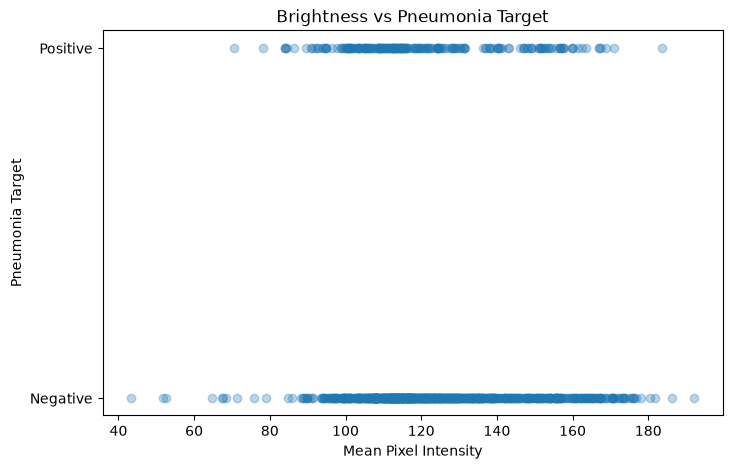

In [18]:
plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    brightness_target["mean_intensity"],
    brightness_target["target"],
    alpha=0.3
)

plt.xlabel(
    "Mean Pixel Intensity"
)

plt.ylabel(
    "Pneumonia Target"
)

plt.title(
    "Brightness vs Pneumonia Target"
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.show()

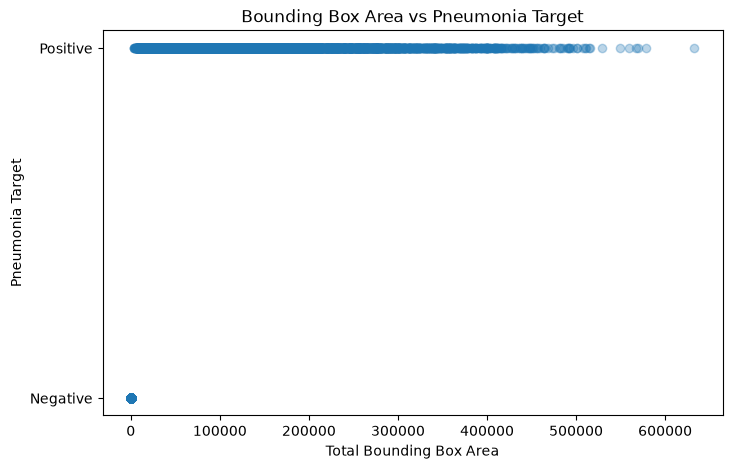

In [19]:
# Relationship 4 — Bounding Box Area vs Target

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    correlation_df["total_bbox_area"],
    correlation_df["target"],
    alpha=0.3
)

plt.xlabel(
    "Total Bounding Box Area"
)

plt.ylabel(
    "Pneumonia Target"
)

plt.title(
    "Bounding Box Area vs Pneumonia Target"
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.show()

In [20]:
# Relationship 5 — Images per Patient

images_per_patient = (
    correlation_df
    .groupby("patient_id")
    .size()
)

images_per_patient.describe()

count    26684.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64

In [21]:
print(
    "Maximum images per patient ID:",
    images_per_patient.max()
)

Maximum images per patient ID: 1


In [22]:
target_correlations = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(
        ascending=False
    )
)

target_correlations

bbox_count         0.991829
max_bbox_area      0.989255
total_bbox_area    0.989255
sex_numeric        0.052386
age_years          0.009681
mean_intensity    -0.097853
width                   NaN
height                  NaN
Name: target, dtype: float64